# Partial-Spoof Source Tracing — Notebook 1 (MFCC version): Train + Val

Same pipeline as the wav2vec2 notebook, but the frozen-SSL feature extractor
is swapped out for **MFCC** features (+ deltas). Everything downstream
(attribution head, localization head, metrics) is untouched because it only
ever reads `FEATURE_DIM` from config -- it doesn't care what produced the
per-frame features.

Each split (`train/`, `val/`) still gets its **own cache subdirectory**, so
there's no risk of filename collisions between splits.

## What this notebook does
1. Extract & cache MFCC(+delta+delta-delta) features for train and val.
2. Train the closed-set attribution head (A01–A06) on train, validate on val.
3. (Optional) Train the frame-level localization head.
4. Save checkpoints to `/kaggle/working/checkpoints/`.

## Data paths used in this notebook
- Train audio: `/kaggle/input/datasets/artharking/train-set-ps/train_set/partialspoof_dataset/audio`
- Train metadata: `/kaggle/input/datasets/artharking/train-set-ps/train_set/partialspoof_dataset/metadata.csv`
- Val audio: `/kaggle/input/datasets/shrekismyhusband/validation-ps/audio`
- Val metadata: `/kaggle/input/datasets/shrekismyhusband/validation-ps/metadata.csv`


## 0. Install & imports
No `transformers`/wav2vec2 needed anymore -- MFCC extraction only needs `librosa`.

In [1]:
!pip install -q librosa soundfile scikit-learn matplotlib


In [2]:
import os
import json
import math
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import soundfile as sf
import librosa

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())


torch: 2.10.0+cu128 | cuda available: True


## 1. Config
Edit the **DATA PATHS** below first if they change. `TEST_*` paths are intentionally absent -- test is handled in Notebook 2.

In [3]:
# ----------------------------- DATA PATHS -----------------------------------
TRAIN_METADATA_CSV = "/kaggle/input/datasets/artharking/train-set-ps/train_set/partialspoof_dataset/metadata.csv"
VAL_METADATA_CSV   = "/kaggle/input/datasets/shrekismyhusband/validation-ps/metadata.csv"

TRAIN_AUDIO_DIR = "/kaggle/input/datasets/artharking/train-set-ps/train_set/partialspoof_dataset/audio"
VAL_AUDIO_DIR   = "/kaggle/input/datasets/shrekismyhusband/validation-ps/audio"

AUDIO_EXT = ".flac"          # change to ".wav" if needed

# Working dir
WORK_DIR = "/kaggle/working"
FEATURE_CACHE_ROOT = os.path.join(WORK_DIR, "feat_cache_mfcc")
# IMPORTANT: separate cache subdirectory per split -- avoids train/val
# filename-collision bugs. Never share one cache dir across splits.
TRAIN_FEATURE_CACHE_DIR = os.path.join(FEATURE_CACHE_ROOT, "train")
VAL_FEATURE_CACHE_DIR = os.path.join(FEATURE_CACHE_ROOT, "val")
CHECKPOINT_DIR = os.path.join(WORK_DIR, "checkpoints")
RESULTS_DIR = os.path.join(WORK_DIR, "results")
for d in [TRAIN_FEATURE_CACHE_DIR, VAL_FEATURE_CACHE_DIR, CHECKPOINT_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ----------------------------- AUDIO / MFCC -----------------------------------
SAMPLE_RATE = 16000

N_MFCC = 40                 # number of MFCC coefficients
MFCC_N_FFT = 400             # 25ms window @ 16kHz
MFCC_HOP_LENGTH = 320         # ~20ms per frame @ 16kHz (kept equal to old wav2vec stride
                              # so sample_to_frame()/clip_segment() need no changes)
USE_DELTA = True             # append delta + delta-delta -> 3x the coefficients
NORMALIZE_MFCC = True         # per-utterance mean/var normalization (CMVN)

FEATURE_DIM = N_MFCC * 3 if USE_DELTA else N_MFCC   # everything downstream reads this

FEATURE_EXTRACTION_BATCH_SIZE = 32   # just a progress-logging chunk size now (no GPU batching needed)
FEATURE_DTYPE = "float16"      # halves disk usage for the cache

# ----------------------------- ATTRIBUTION HEAD ------------------------------
KNOWN_ATTACKS = ["A01", "A02", "A03", "A04", "A05", "A06"]   # train/val label set
NUM_KNOWN_CLASSES = len(KNOWN_ATTACKS)

EMBED_DIM = 256
USE_AAM = True          # AAM-Softmax (margin) vs plain softmax classifier
AAM_MARGIN = 0.2
AAM_SCALE = 30.0

ATTR_BATCH_SIZE = 64
ATTR_EPOCHS = 40
ATTR_LR = 1e-3
ATTR_WEIGHT_DECAY = 1e-4
ATTR_EARLY_STOP_PATIENCE = 8

MIN_SEGMENT_FRAMES = 2   # guard against degenerate ultra-short spoof spans

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
print("Device:", DEVICE)
print("FEATURE_DIM:", FEATURE_DIM)


Device: cuda
FEATURE_DIM: 120


## 2. Sample-index <-> frame-index helpers

In [4]:
def sample_to_frame(sample_idx: int, stride: int = MFCC_HOP_LENGTH) -> int:
    """Approximate conversion from a raw sample index to an MFCC frame index
    (hop ~320 samples/frame @ 16kHz). Accurate to +/- 1-2 frames."""
    return int(sample_idx // stride)


def clip_segment(frame_start: int, frame_end: int, num_frames: int, min_len: int = 1):
    """Clip a [start, end) frame range to valid bounds, guaranteeing >= min_len frames."""
    frame_start = max(0, min(frame_start, num_frames - 1))
    frame_end = max(frame_start + min_len, min(frame_end, num_frames))
    frame_end = min(frame_end, num_frames)
    if frame_end <= frame_start:
        frame_start = max(0, num_frames - min_len)
        frame_end = num_frames
    return frame_start, frame_end


## 3. STEP 1 — Extract & cache MFCC features (train + val)
Each split writes to its **own** cache subdirectory -- no collision possible.

In [5]:
def load_audio(path: str, target_sr: int = SAMPLE_RATE) -> np.ndarray:
    wav, sr = sf.read(path, dtype="float32")
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    if sr != target_sr:
        wav = librosa.resample(wav, orig_sr=sr, target_sr=target_sr)
    return wav


def extract_mfcc_features(wav: np.ndarray) -> np.ndarray:
    """Returns (T, FEATURE_DIM) array: MFCC (+ delta + delta-delta if enabled),
    optionally per-utterance mean/var normalized."""
    mfcc = librosa.feature.mfcc(
        y=wav, sr=SAMPLE_RATE, n_mfcc=N_MFCC,
        n_fft=MFCC_N_FFT, hop_length=MFCC_HOP_LENGTH,
    )  # (n_mfcc, T)

    if USE_DELTA:
        delta1 = librosa.feature.delta(mfcc, order=1)
        delta2 = librosa.feature.delta(mfcc, order=2)
        feat = np.concatenate([mfcc, delta1, delta2], axis=0)  # (FEATURE_DIM, T)
    else:
        feat = mfcc

    feat = feat.T  # (T, FEATURE_DIM)

    if NORMALIZE_MFCC:
        mean = feat.mean(axis=0, keepdims=True)
        std = feat.std(axis=0, keepdims=True)
        feat = (feat - mean) / (std + 1e-5)

    return feat.astype(FEATURE_DTYPE)


def process_split(metadata_csv, audio_dir, cache_dir, split_name):
    if not os.path.exists(metadata_csv):
        print(f"[skip] {split_name}: metadata not found at {metadata_csv}")
        return
    df = pd.read_csv(metadata_csv)

    todo = []
    for fname in df["file"]:
        out_path = os.path.join(cache_dir, fname.replace(AUDIO_EXT, ".npy"))
        if not os.path.exists(out_path):
            todo.append(fname)
    print(f"[{split_name}] {len(todo)}/{len(df)} files need feature extraction (cache: {cache_dir}).")

    t0 = time.time()
    for i, fname in enumerate(todo):
        path = os.path.join(audio_dir, fname)
        if not os.path.exists(path):
            print(f"  [warn] missing audio file: {path}")
            continue

        wav = load_audio(path)
        feat = extract_mfcc_features(wav)

        out_path = os.path.join(cache_dir, fname.replace(AUDIO_EXT, ".npy"))
        np.save(out_path, feat)

        if i % (FEATURE_EXTRACTION_BATCH_SIZE * 20) == 0 and i > 0:
            elapsed = time.time() - t0
            rate = i / max(elapsed, 1e-6)
            eta = (len(todo) - i) / max(rate, 1e-6)
            print(f"  [{split_name}] {i}/{len(todo)} done | {rate:.1f} files/s | ETA {eta/60:.1f} min")

    print(f"[{split_name}] feature extraction complete.")


In [6]:
process_split(TRAIN_METADATA_CSV, TRAIN_AUDIO_DIR, TRAIN_FEATURE_CACHE_DIR, "train")
process_split(VAL_METADATA_CSV, VAL_AUDIO_DIR, VAL_FEATURE_CACHE_DIR, "val")

print("Train+val feature extraction done.")
print("Train cache:", TRAIN_FEATURE_CACHE_DIR)
print("Val cache:", VAL_FEATURE_CACHE_DIR)


[train] 22800/22800 files need feature extraction (cache: /kaggle/working/feat_cache_mfcc/train).
  [train] 640/22800 done | 30.6 files/s | ETA 12.1 min
  [train] 1280/22800 done | 44.0 files/s | ETA 8.2 min
  [train] 1920/22800 done | 51.5 files/s | ETA 6.8 min
  [train] 2560/22800 done | 56.4 files/s | ETA 6.0 min
  [train] 3200/22800 done | 59.9 files/s | ETA 5.5 min
  [train] 3840/22800 done | 62.5 files/s | ETA 5.1 min
  [train] 4480/22800 done | 64.5 files/s | ETA 4.7 min
  [train] 5120/22800 done | 66.1 files/s | ETA 4.5 min
  [train] 5760/22800 done | 67.0 files/s | ETA 4.2 min
  [train] 6400/22800 done | 67.9 files/s | ETA 4.0 min
  [train] 7040/22800 done | 68.7 files/s | ETA 3.8 min
  [train] 7680/22800 done | 69.4 files/s | ETA 3.6 min
  [train] 8320/22800 done | 70.0 files/s | ETA 3.4 min
  [train] 8960/22800 done | 70.5 files/s | ETA 3.3 min
  [train] 9600/22800 done | 71.0 files/s | ETA 3.1 min
  [train] 10240/22800 done | 71.2 files/s | ETA 2.9 min
  [train] 10880/22800

## 4. Datasets (each instance is bound to one split's cache dir -- no collision possible)

In [7]:
def _load_cached(cache_dir: str, fname: str) -> np.ndarray:
    path = os.path.join(cache_dir, fname.replace(AUDIO_EXT, ".npy"))
    return np.load(path).astype(np.float32)


class AttributionDataset(Dataset):
    """Returns (spoof_segment_features [T', D], label_idx, attack_str).
    `cache_dir` must be the cache directory for THIS split specifically."""

    def __init__(self, metadata_csv: str, cache_dir: str, label_encoder: dict = None):
        self.cache_dir = cache_dir
        self.df = pd.read_csv(metadata_csv).reset_index(drop=True)
        exists_mask = self.df["file"].apply(
            lambda f: os.path.exists(os.path.join(cache_dir, f.replace(AUDIO_EXT, ".npy")))
        )
        dropped = (~exists_mask).sum()
        if dropped:
            print(f"[AttributionDataset:{cache_dir}] dropping {dropped} rows with no cached features")
        self.df = self.df[exists_mask].reset_index(drop=True)

        if label_encoder is None:
            label_encoder = {a: i for i, a in enumerate(KNOWN_ATTACKS)}
        self.label_encoder = label_encoder

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        feat = _load_cached(self.cache_dir, row["file"])
        num_frames = feat.shape[0]

        f_start = sample_to_frame(int(row["start"]))
        f_end = sample_to_frame(int(row["end"]))
        f_start, f_end = clip_segment(f_start, f_end, num_frames, min_len=MIN_SEGMENT_FRAMES)

        segment = feat[f_start:f_end]
        label = self.label_encoder.get(row["attack"], -1)
        return torch.from_numpy(segment), label, row["attack"]


def attribution_collate(batch):
    segments, labels, attacks = zip(*batch)
    lengths = [s.shape[0] for s in segments]
    max_len = max(lengths)
    dim = segments[0].shape[1]

    padded = torch.zeros(len(segments), max_len, dim)
    mask = torch.zeros(len(segments), max_len, dtype=torch.bool)
    for i, s in enumerate(segments):
        padded[i, :s.shape[0]] = s
        mask[i, :s.shape[0]] = True

    labels = torch.tensor(labels, dtype=torch.long)
    return padded, mask, labels, list(attacks)


In [8]:
class Conv2DBlockFeature(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        is_first_block: bool = False,
        pool_size=(1, 2),
    ):
        super().__init__()

        self.normalizer = None

        if not is_first_block:
            self.normalizer = nn.Sequential(
                nn.BatchNorm2d(in_channels),
                nn.SELU(inplace=True),
            )

        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=(2, 5),
                padding=(1, 2),
            ),
            nn.BatchNorm2d(out_channels),
            nn.SELU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=(2, 3),
                padding=(0, 1),
            ),
        )

        self.downsampler = None

        if in_channels != out_channels:
            self.downsampler = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=(1, 3),
                padding=(0, 1),
            )

        # Much smaller temporal pooling
        self.pooling = nn.MaxPool2d(
            kernel_size=pool_size,
            stride=pool_size,
            ceil_mode=True,
        )

    def forward(self, x):

        identity = x

        if self.downsampler is not None:
            identity = self.downsampler(identity)

        if self.normalizer is not None:
            x = self.normalizer(x)

        x = self.layers(x) + identity

        x = self.pooling(x)

        return x

In [9]:
class FeatureFrontend(nn.Module):

    def __init__(self, feature_dim):
        super().__init__()

        self.conv_blocks = nn.Sequential(

            Conv2DBlockFeature(
                in_channels=1,
                out_channels=32,
                is_first_block=True,
                pool_size=(1, 2),
            ),

            Conv2DBlockFeature(
                in_channels=32,
                out_channels=32,
                pool_size=(1, 2),
            ),

            Conv2DBlockFeature(
                in_channels=32,
                out_channels=64,
                pool_size=(1, 2),
            ),

            Conv2DBlockFeature(
                in_channels=64,
                out_channels=64,
                pool_size=(1, 2),
            ),
        )

    def forward(self, x):

        # x: [B, T, D]

        # [B, T, D]
        # → [B, D, T]
        x = x.transpose(1, 2)

        # → [B, 1, D, T]
        x = x.unsqueeze(1)

        x = self.conv_blocks(x)

        return x

In [10]:
class MaskedSequencePooling(nn.Module):
    """
    Input:
        x    : [B, S, C]
        mask : [B, S]

    Output:
        [B, C]
    """

    def __init__(self, d_model):
        super().__init__()

        self.linear = nn.Linear(d_model, 1)

    def forward(self, x, mask=None):

        # [B, S, C] → [B, S, 1]
        w = self.linear(x)

        if mask is not None:

            # Padding positions get -inf
            w = w.masked_fill(
                ~mask.unsqueeze(-1),
                float("-inf")
            )

        # Attention weights over sequence
        w = F.softmax(w, dim=1)

        # Weighted sum
        out = torch.sum(w * x, dim=1)

        return out

In [11]:
class WaveletFANFeatureMap(nn.Module):
    """
    Bump Wavelet FAN (SAFE)
    """
    def __init__(self, d_head, d_phi=None):
        super().__init__()
        if d_phi is None:
            d_phi = d_head
        assert d_phi % 2 == 0

        self.linear_p = nn.Linear(d_head, d_phi // 2)
        self.linear_g = nn.Linear(d_head, d_phi // 2)
        self.act = nn.GELU()

        self.log_scale = nn.Parameter(torch.zeros(1))
        self.gate = nn.Parameter(torch.randn(1))

    def forward(self, x):
        z = self.linear_p(x)
        g = self.act(self.linear_g(x))

        s = torch.exp(self.log_scale) + 1e-4  # slightly larger eps
        u = z / s

        # ---- Bump wavelet (SAFE) ----
        wavelet = torch.zeros_like(u)
        mask = (u.abs() < 1.0)
        
        wavelet[mask] = torch.exp(-1.0 / (1.0 - u[mask]**2))
        wavelet = wavelet / (wavelet.std(dim=-1, keepdim=True) + 1e-5)




        gate = torch.sigmoid(self.gate)

        return torch.cat([
            gate * wavelet,
            (1 - gate) * g
        ], dim=-1)

# -------------------------------
# Multi-Head Wavelet-FAN
# -------------------------------
class MultiHeadWaveletFAN(nn.Module):
    def __init__(self, d_model, n_head=8, d_head=None):
        super().__init__()
        self.n_head = n_head
        if d_head is None:
            assert d_model % n_head == 0
            d_head = d_model // n_head
        self.d_head = d_head

        self.heads = nn.ModuleList([
            WaveletFANFeatureMap(d_head)
            for _ in range(n_head)
        ])

        self.out_proj = nn.Linear(n_head * d_head, d_model)

    def forward(self, x):
        B, S, D = x.shape
        x = x.view(B, S, self.n_head, self.d_head).permute(0, 2, 1, 3)

        head_outs = []
        for h in range(self.n_head):
            head_outs.append(self.heads[h](x[:, h]))

        out = torch.cat(head_outs, dim=-1)
        return self.out_proj(out)

class LayerNorm(nn.Module):
    def __init__(self, d_model, eps=1e-12):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x):
        mean = x.mean(-1, keepdim=True)
        var = x.var(-1, unbiased=False, keepdim=True)
        xhat = (x - mean) / torch.sqrt(var + self.eps)
        return self.gamma * xhat + self.beta
class FFN(nn.Module):
    def __init__(self, d_model, ffn_hidden, drop_prob=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, ffn_hidden),
            nn.ReLU(),
            nn.Dropout(drop_prob),
            nn.Linear(ffn_hidden, d_model),
        )

    def forward(self, x):
        return self.net(x)
# -------------------------------
# Wavelet Transformer Encoder Layer
# -------------------------------
class TransformerEncoderLayerWaveletFAN(nn.Module):
    def __init__(self, d_model=64, n_head=8, ffn_hidden=2048, drop_prob=0.1):
        super().__init__()

        self.attn = MultiHeadWaveletFAN(d_model, n_head)
        self.dropout1 = nn.Dropout(drop_prob)
        self.norm1 = LayerNorm(d_model)

        self.ffn = FFN(d_model, ffn_hidden, drop_prob)
        self.dropout2 = nn.Dropout(drop_prob)
        self.norm2 = LayerNorm(d_model)

    def forward(self, x):
        residual = x
        x = self.attn(x)
        x = self.dropout1(x)
        x = self.norm1(x + residual)

        residual = x
        x = self.ffn(x)
        x = self.dropout2(x)
        x = self.norm2(x + residual)
        return x



In [12]:
class FeatureRawformerClassifier(nn.Module):

    def __init__(
        self,
        C=64,
        n_encoder=2,
        transformer_hidden=2048,
        embedding_dim=128,
    ):
        super().__init__()

        self.encoders = nn.ModuleList([
            TransformerEncoderLayerWaveletFAN(
                d_model=C,
                n_head=8,
                ffn_hidden=transformer_hidden,
            )
            for _ in range(n_encoder)
        ])

        self.seq_pool = MaskedSequencePooling(
            d_model=C
        )

        self.embedding = nn.Sequential(
            nn.Linear(C, embedding_dim),
            nn.BatchNorm1d(embedding_dim),
        )

    def forward(self, x, mask=None):

        for encoder in self.encoders:
            x = encoder(x)

        x = self.seq_pool(x, mask)

        return self.embedding(x)

In [13]:
class PositionalAggregator1D(nn.Module):

    def __init__(
        self,
        max_C=64,
        max_ft=5000,
    ):
        super().__init__()

        position = torch.arange(
            max_ft
        ).float().unsqueeze(1)

        div_term = torch.exp(
            torch.arange(
                0,
                max_C,
                2
            ).float()
            *
            (-math.log(10000.0) / max_C)
        )

        encoding = torch.zeros(
            max_ft,
            max_C
        )

        encoding[:, 0::2] = torch.sin(
            position * div_term
        )

        encoding[:, 1::2] = torch.cos(
            position * div_term
        )

        self.register_buffer(
            "encoding",
            encoding
        )

    def forward(self, HFM):

        # HFM: [B, C, f, t]

        B, C, f, t = HFM.shape

        # [B, C, f, t]
        # → [B, C, f*t]
        x = HFM.flatten(
            start_dim=2
        )

        # → [B, f*t, C]
        x = x.transpose(1, 2)

        S = x.size(1)

        x = x + self.encoding[
            :S,
            :C
        ].unsqueeze(0)

        return x

In [14]:
class FeatureRawformerAttributionModel(nn.Module):

    def __init__(
        self,
        feature_dim=FEATURE_DIM,
        embed_dim=EMBED_DIM,
        num_classes=NUM_KNOWN_CLASSES,
        use_aam=USE_AAM,
        transformer_hidden=2048,
        n_encoder=2,
        max_sequence_length=5000,
    ):
        super().__init__()

        # ----------------------------------
        # Feature input frontend
        # ----------------------------------
        self.front_end = FeatureFrontend(
            feature_dim=feature_dim
        )

        # ----------------------------------
        # Positional aggregation
        # ----------------------------------
        self.positional_embedding = PositionalAggregator1D(
            max_C=64,
            max_ft=max_sequence_length,
        )

        # ----------------------------------
        # Wavelet-FAN Rawformer classifier
        # ----------------------------------
        self.encoder = FeatureRawformerClassifier(
            C=64,
            n_encoder=n_encoder,
            transformer_hidden=transformer_hidden,
            embedding_dim=embed_dim,
        )

        # ----------------------------------
        # Final attack classifier
        # ----------------------------------
        self.use_aam = use_aam

        if use_aam:

            self.classifier = AAMSoftmax(
                in_dim=embed_dim,
                num_classes=num_classes,
            )

        else:

            self.classifier = nn.Linear(
                embed_dim,
                num_classes
            )

    def embedding(self, x, mask=None):

        """
        Input:
            x    : [B, T, D]
            mask : [B, T]

        Output:
            emb  : [B, embed_dim]
        """

        # ------------------------------
        # Feature frontend
        # ------------------------------
        x = self.front_end(x)

        # x:
        # [B, 64, f, t]

        # ------------------------------
        # Flatten f × t into sequence
        # ------------------------------
        x = self.positional_embedding(x)

        # x:
        # [B, f*t, 64]

        # NOTE:
        # For now, mask is not directly compatible
        # because Conv2D + pooling changes T.
        #
        # We will handle this properly below.
        emb = self.encoder(
            x,
            mask=None
        )

        return emb

    def forward(
        self,
        x,
        mask=None,
        labels=None
    ):

        emb = self.embedding(
            x,
            mask
        )

        if self.use_aam:

            logits = self.classifier(
                emb,
                labels
            )

        else:

            logits = self.classifier(
                emb
            )

        return logits, emb

## 5. Models: pooling + attribution head

In [15]:
class StatsPooling(nn.Module):
    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        mask_f = mask.unsqueeze(-1).float()
        lengths = mask_f.sum(dim=1).clamp(min=1.0)
        mean = (x * mask_f).sum(dim=1) / lengths
        var = ((x - mean.unsqueeze(1)) ** 2 * mask_f).sum(dim=1) / lengths
        std = torch.sqrt(var.clamp(min=1e-8))
        return torch.cat([mean, std], dim=-1)


class AAMSoftmax(nn.Module):
    """Additive Angular Margin (ArcFace-style) classifier -- tends to produce
    embeddings that generalize better to unseen classes at test time."""

    def __init__(self, in_dim, num_classes, margin=AAM_MARGIN, scale=AAM_SCALE):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(num_classes, in_dim))
        nn.init.xavier_normal_(self.weight)
        self.margin = margin
        self.scale = scale
        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)
        self.th = math.cos(math.pi - margin)
        self.mm = math.sin(math.pi - margin) * margin

    def forward(self, x, labels=None):
        x_norm = F.normalize(x, dim=-1)
        w_norm = F.normalize(self.weight, dim=-1)
        cosine = F.linear(x_norm, w_norm)

        if labels is None or (labels < 0).all():
            return cosine * self.scale

        sine = torch.sqrt((1.0 - cosine ** 2).clamp(0, 1))
        phi = cosine * self.cos_m - sine * self.sin_m
        phi = torch.where(cosine > self.th, phi, cosine - self.mm)

        one_hot = torch.zeros_like(cosine)
        valid = labels >= 0
        one_hot[valid] = F.one_hot(labels[valid], num_classes=cosine.shape[1]).float()

        logits = torch.where(one_hot.bool(), phi, cosine) * self.scale
        return logits


# class AttributionModel(nn.Module):
#     def __init__(self, feature_dim=FEATURE_DIM, embed_dim=EMBED_DIM,
#                  num_classes=NUM_KNOWN_CLASSES, use_aam=USE_AAM):
#         super().__init__()
#         self.pool = StatsPooling()
#         self.proj = nn.Sequential(
#             nn.Linear(feature_dim * 2, embed_dim),
#             nn.BatchNorm1d(embed_dim),
#             nn.ReLU(),
#             nn.Linear(embed_dim, embed_dim),
#         )
#         self.use_aam = use_aam
#         if use_aam:
#             self.classifier = AAMSoftmax(embed_dim, num_classes)
#         else:
#             self.classifier = nn.Linear(embed_dim, num_classes)

#     def embedding(self, x, mask):
#         pooled = self.pool(x, mask)
#         return self.proj(pooled)

#     def forward(self, x, mask, labels=None):
#         emb = self.embedding(x, mask)
#         if self.use_aam:
#             logits = self.classifier(emb, labels)
#         else:
#             logits = self.classifier(emb)
#         return logits, emb


## 6. STEP 2 — Train the closed-set attribution model (A01–A06)
Trains on train, validates on val -- both are separate, correctly-namespaced caches.

In [16]:
# def run_attr_epoch(model, loader, optimizer=None):
#     training = optimizer is not None
#     model.train() if training else model.eval()

#     all_preds, all_labels = [], []
#     total_loss, n_batches = 0.0, 0
#     ce = nn.CrossEntropyLoss()

#     with torch.set_grad_enabled(training):
#         for feats, mask, labels, _ in loader:
#             feats, mask, labels = feats.to(DEVICE), mask.to(DEVICE), labels.to(DEVICE)
#             logits, _ = model(feats, mask, labels if training else None)
#             loss = ce(logits, labels)

#             if training:
#                 optimizer.zero_grad()
#                 loss.backward()
#                 optimizer.step()

#             total_loss += loss.item()
#             n_batches += 1
#             preds = logits.argmax(dim=-1).detach().cpu().numpy()
#             all_preds.extend(preds.tolist())
#             all_labels.extend(labels.detach().cpu().numpy().tolist())

#     acc = accuracy_score(all_labels, all_preds)
#     f1 = f1_score(all_labels, all_preds, average="macro")
#     return total_loss / max(n_batches, 1), acc, f1, all_labels, all_preds

from tqdm.auto import tqdm

from tqdm.auto import tqdm

def run_attr_epoch(model, loader, optimizer=None, epoch=None):

    training = optimizer is not None

    if training:
        model.train()
        desc = f"Epoch {epoch:03d} | Train"
    else:
        model.eval()
        desc = f"Epoch {epoch:03d} | Val"

    all_preds = []
    all_labels = []

    total_loss = 0.0
    n_batches = 0

    criterion = nn.CrossEntropyLoss()

    progress_bar = tqdm(
        loader,
        desc=desc,
        leave=False,
        dynamic_ncols=True
    )

    with torch.set_grad_enabled(training):

        for feats, mask, labels, _ in progress_bar:

            feats = feats.to(
                DEVICE,
                non_blocking=True
            )

            mask = mask.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            # ==================================================
            # FORWARD PASS
            # ==================================================

            logits, embeddings = model(
                feats,
                mask,
                labels if USE_AAM else None
            )

            loss = criterion(
                logits,
                labels
            )

            # ==================================================
            # BACKPROPAGATION
            # ==================================================

            if training:

                optimizer.zero_grad(
                    set_to_none=True
                )

                loss.backward()

                optimizer.step()

            # ==================================================
            # STORE RESULTS
            # ==================================================

            total_loss += loss.item()
            n_batches += 1

            preds = torch.argmax(
                logits,
                dim=-1
            )

            all_preds.extend(
                preds.detach().cpu().tolist()
            )

            all_labels.extend(
                labels.detach().cpu().tolist()
            )

            # ==================================================
            # RUNNING METRICS
            # ==================================================

            running_loss = total_loss / n_batches

            progress_bar.set_postfix(
                loss=f"{running_loss:.4f}"
            )

    # ==========================================================
    # FINAL EPOCH METRICS
    # ==========================================================

    avg_loss = total_loss / max(n_batches, 1)

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return (
        avg_loss,
        acc,
        f1,
        all_labels,
        all_preds
    )

In [17]:
# ============================================================
# LABEL ENCODER
# ============================================================

attr_label_encoder = {
    attack: i
    for i, attack in enumerate(KNOWN_ATTACKS)
}


# ============================================================
# DATASETS
# ============================================================

train_ds = AttributionDataset(
    TRAIN_METADATA_CSV,
    TRAIN_FEATURE_CACHE_DIR,
    attr_label_encoder
)

val_ds = AttributionDataset(
    VAL_METADATA_CSV,
    VAL_FEATURE_CACHE_DIR,
    attr_label_encoder
)

print(
    f"train samples: {len(train_ds)} "
    f"| val samples: {len(val_ds)}"
)


# ============================================================
# DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_ds,
    batch_size=ATTR_BATCH_SIZE,
    shuffle=True,
    collate_fn=attribution_collate,
    num_workers=0,
    pin_memory=True,
)

val_loader = DataLoader(
    val_ds,
    batch_size=ATTR_BATCH_SIZE,
    shuffle=False,
    collate_fn=attribution_collate,
    num_workers=0,
    pin_memory=True,
)


# ============================================================
# MODEL
# ============================================================

attribution_model = FeatureRawformerAttributionModel(
    feature_dim=FEATURE_DIM,
    embed_dim=EMBED_DIM,
    num_classes=NUM_KNOWN_CLASSES,
    use_aam=USE_AAM,
    transformer_hidden=2048,
    n_encoder=2,
    max_sequence_length=20000,
).to(DEVICE)

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    attribution_model.parameters(),
    lr=ATTR_LR,
    weight_decay=ATTR_WEIGHT_DECAY,
)


# ============================================================
# LEARNING RATE SCHEDULER
# ============================================================

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
)


# ============================================================
# TRAINING VARIABLES
# ============================================================

best_val_f1 = -1.0

patience_counter = 0

attr_ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    "attribution_model_rawformer_wavelet_mfcc.pt"
)


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    ATTR_EPOCHS + 1
):

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    train_loss, train_acc, train_f1, _, _ = run_attr_epoch(
        model=attribution_model,
        loader=train_loader,
        optimizer=optimizer,
        epoch=epoch,
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss, val_acc, val_f1, val_labels, val_preds = run_attr_epoch(
        model=attribution_model,
        loader=val_loader,
        optimizer=None,
        epoch=epoch,
    )


    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step(
        val_f1
    )


    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"epoch {epoch:03d} "
        f"| lr {current_lr:.2e} "
        f"| train loss {train_loss:.4f} "
        f"acc {train_acc:.4f} "
        f"f1 {train_f1:.4f} "
        f"| val loss {val_loss:.4f} "
        f"acc {val_acc:.4f} "
        f"f1 {val_f1:.4f}"
    )


    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        patience_counter = 0

        torch.save(
            {

                "model_state":
                    attribution_model.state_dict(),

                "label_encoder":
                    attr_label_encoder,

                "config": {

                    # Feature configuration
                    "feature_dim":
                        FEATURE_DIM,

                    "feature_type":
                        "mfcc",

                    "n_mfcc":
                        N_MFCC,

                    "use_delta":
                        USE_DELTA,

                    "normalize_mfcc":
                        NORMALIZE_MFCC,

                    "mfcc_n_fft":
                        MFCC_N_FFT,

                    "mfcc_hop_length":
                        MFCC_HOP_LENGTH,

                    "sample_rate":
                        SAMPLE_RATE,

                    "min_segment_frames":
                        MIN_SEGMENT_FRAMES,


                    # Model configuration
                    "model_type":
                        "FeatureRawformerWaveletFAN",

                    "embed_dim":
                        EMBED_DIM,

                    "num_classes":
                        NUM_KNOWN_CLASSES,

                    "use_aam":
                        USE_AAM,

                    "transformer_hidden":
                        2048,

                    "n_encoder":
                        2,

                    "max_sequence_length":
                        5000,
                },


                # Validation results
                "val_f1":
                    val_f1,

                "val_acc":
                    val_acc,

                "epoch":
                    epoch,
            },

            attr_ckpt_path
        )


        # ----------------------------------------------------
        # Save confusion matrix
        # ----------------------------------------------------

        cm = confusion_matrix(
            val_labels,
            val_preds,
            labels=list(
                range(NUM_KNOWN_CLASSES)
            )
        )

        np.save(
            os.path.join(
                RESULTS_DIR,
                "val_confusion_matrix_rawformer_wavelet_mfcc.npy"
            ),
            cm
        )

        print(
            f"  ✓ Best model saved "
            f"(val F1 = {val_f1:.4f})"
        )


    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    else:

        patience_counter += 1

        if patience_counter >= ATTR_EARLY_STOP_PATIENCE:

            print(
                f"\nEarly stopping at epoch {epoch} "
                f"(best val F1 = {best_val_f1:.4f})"
            )

            break


# ============================================================
# FINAL RESULT
# ============================================================

print(
    f"\nBest validation macro-F1: "
    f"{best_val_f1:.4f}"
)

print(
    f"Checkpoint saved to:\n"
    f"{attr_ckpt_path}"
)


train samples: 22800 | val samples: 22995


Epoch 001 | Train:   0%|          | 0/357 [00:00<?, ?it/s]

Epoch 001 | Val:   0%|          | 0/360 [00:00<?, ?it/s]

epoch 001 | lr 1.00e-03 | train loss 4.7471 acc 0.2900 f1 0.2850 | val loss 6.9649 acc 0.2297 f1 0.1826
  ✓ Best model saved (val F1 = 0.1826)


Epoch 002 | Train:   0%|          | 0/357 [00:00<?, ?it/s]

...

Epoch 039 | Val:   0%|          | 0/360 [00:00<?, ?it/s]

epoch 039 | lr 2.50e-04 | train loss 0.0534 acc 0.9889 f1 0.9890 | val loss 0.5487 acc 0.9257 f1 0.9270


Epoch 040 | Train:   0%|          | 0/357 [00:00<?, ?it/s]

Epoch 040 | Val:   0%|          | 0/360 [00:00<?, ?it/s]

epoch 040 | lr 2.50e-04 | train loss 0.0485 acc 0.9895 f1 0.9896 | val loss 0.6216 acc 0.9202 f1 0.9210

Best validation macro-F1: 0.9296
Checkpoint saved to:
/kaggle/working/checkpoints/attribution_model_rawformer_wavelet_mfcc.pt


## 7. STEP 3 (optional) — Localization model (frame-level fake/true tagging)
This is a **different task** from attribution above: instead of "which
algorithm made this fake," it predicts real/fake for every ~20ms frame across
the *whole file*. Uses the same cached MFCC features from Step 1, just
without cropping to the spoof span -- every frame keeps its own real/fake
label derived from `start`/`end`.

In [18]:
LOC_MAX_FRAMES = 200     # ~8s of audio at 20ms/frame; truncate/pad to this
LOC_BATCH_SIZE = 32
LOC_EPOCHS = 20
LOC_LR = 1e-3
LOC_HIDDEN_DIM = 128

def make_frame_labels(num_frames: int, spoof_frame_start: int, spoof_frame_end: int) -> np.ndarray:
    """Binary per-frame label array: 1 = spoof/fake, 0 = bonafide/true."""
    labels = np.zeros(num_frames, dtype=np.int64)
    s, e = clip_segment(spoof_frame_start, spoof_frame_end, num_frames)
    labels[s:e] = 1
    return labels


class LocalizationDataset(Dataset):
    """Returns (full-file features truncated/padded to LOC_MAX_FRAMES,
    frame-level binary labels, mask). `cache_dir` must be the cache
    directory for THIS split specifically (same collision-safety rule as
    AttributionDataset above)."""

    def __init__(self, metadata_csv: str, cache_dir: str):
        self.cache_dir = cache_dir
        self.df = pd.read_csv(metadata_csv).reset_index(drop=True)
        exists_mask = self.df["file"].apply(
            lambda f: os.path.exists(os.path.join(cache_dir, f.replace(AUDIO_EXT, ".npy")))
        )
        self.df = self.df[exists_mask].reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        feat = _load_cached(self.cache_dir, row["file"])
        num_frames = feat.shape[0]

        f_start = sample_to_frame(int(row["start"]))
        f_end = sample_to_frame(int(row["end"]))
        labels = make_frame_labels(num_frames, f_start, f_end)

        max_len = LOC_MAX_FRAMES
        if num_frames >= max_len:
            feat = feat[:max_len]
            labels = labels[:max_len]
            mask = np.ones(max_len, dtype=bool)
        else:
            pad_len = max_len - num_frames
            feat = np.concatenate([feat, np.zeros((pad_len, feat.shape[1]), dtype=feat.dtype)], axis=0)
            labels = np.concatenate([labels, np.zeros(pad_len, dtype=labels.dtype)], axis=0)
            mask = np.concatenate([np.ones(num_frames, dtype=bool), np.zeros(pad_len, dtype=bool)], axis=0)

        return torch.from_numpy(feat), torch.from_numpy(labels), torch.from_numpy(mask), row["file"]


def loc_collate(batch):
    feats, labels, masks, fnames = zip(*batch)
    return torch.stack(feats), torch.stack(labels), torch.stack(masks), list(fnames)


In [19]:
class LocalizationModel(nn.Module):
    """BiLSTM frame tagger: predicts per-frame real(0)/fake(1) logits.
    This is the 'Hypothesis' generator for the segment-level metric below."""

    def __init__(self, feature_dim=FEATURE_DIM, hidden_dim=LOC_HIDDEN_DIM):
        super().__init__()
        self.lstm = nn.LSTM(feature_dim, hidden_dim, num_layers=1,
                             batch_first=True, bidirectional=True)
        self.classifier = nn.Linear(hidden_dim * 2, 2)

    def forward(self, x, mask):
        lengths = mask.sum(dim=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.shape[1])
        return self.classifier(out)   # (B, T, 2)


In [20]:
def run_loc_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    ce = nn.CrossEntropyLoss(reduction="none")

    total_loss, n_batches = 0.0, 0
    all_preds, all_labels = [], []

    with torch.set_grad_enabled(training):
        for feats, labels, mask, _ in loader:
            feats, labels, mask = feats.to(DEVICE), labels.to(DEVICE), mask.to(DEVICE)
            logits = model(feats, mask)

            loss_per_frame = ce(logits.transpose(1, 2), labels)
            loss = (loss_per_frame * mask).sum() / mask.sum().clamp(min=1)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1
            preds = logits.argmax(dim=-1)
            all_preds.extend(preds[mask].detach().cpu().numpy().tolist())
            all_labels.extend(labels[mask].detach().cpu().numpy().tolist())

    f1 = f1_score(all_labels, all_preds, average="binary")
    return total_loss / max(n_batches, 1), f1


loc_train_ds = LocalizationDataset(TRAIN_METADATA_CSV, TRAIN_FEATURE_CACHE_DIR)
loc_val_ds = LocalizationDataset(VAL_METADATA_CSV, VAL_FEATURE_CACHE_DIR)
print(f"loc train samples: {len(loc_train_ds)} | loc val samples: {len(loc_val_ds)}")

loc_train_loader = DataLoader(loc_train_ds, batch_size=LOC_BATCH_SIZE, shuffle=True,
                               collate_fn=loc_collate, num_workers=2)
loc_val_loader = DataLoader(loc_val_ds, batch_size=LOC_BATCH_SIZE, shuffle=False,
                             collate_fn=loc_collate, num_workers=2)

localization_model = LocalizationModel().to(DEVICE)
loc_optimizer = torch.optim.AdamW(localization_model.parameters(), lr=LOC_LR)

best_loc_f1 = -1.0
loc_ckpt_path = os.path.join(CHECKPOINT_DIR, "localization_model_mfcc.pt")

for epoch in range(1, LOC_EPOCHS + 1):
    train_loss, train_f1 = run_loc_epoch(localization_model, loc_train_loader, loc_optimizer)
    val_loss, val_f1 = run_loc_epoch(localization_model, loc_val_loader, optimizer=None)
    print(f"epoch {epoch:03d} | train loss {train_loss:.4f} f1 {train_f1:.4f} "
          f"| val loss {val_loss:.4f} f1 {val_f1:.4f}")

    if val_f1 > best_loc_f1:
        best_loc_f1 = val_f1
        torch.save({
            "model_state": localization_model.state_dict(),
            "val_f1": val_f1,
            "config": {"feature_dim": FEATURE_DIM, "hidden_dim": LOC_HIDDEN_DIM,
                       "loc_max_frames": LOC_MAX_FRAMES,
                       "feature_type": "mfcc", "mfcc_hop_length": MFCC_HOP_LENGTH},
        }, loc_ckpt_path)

print(f"Best val frame-level F1: {best_loc_f1:.4f}. Checkpoint saved to {loc_ckpt_path}")


loc train samples: 22800 | loc val samples: 22995
epoch 001 | train loss 0.1681 f1 0.9245 | val loss 0.2826 f1 0.8634
epoch 002 | train loss 0.0686 f1 0.9713 | val loss 0.2968 f1 0.8903
epoch 003 | train loss 0.0379 f1 0.9845 | val loss 0.3610 f1 0.8901
epoch 004 | train loss 0.0362 f1 0.9849 | val loss 0.3404 f1 0.8932
epoch 005 | train loss 0.0257 f1 0.9893 | val loss 0.3526 f1 0.9025
epoch 006 | train loss 0.0210 f1 0.9911 | val loss 0.3668 f1 0.9009
epoch 007 | train loss 0.0292 f1 0.9879 | val loss 0.3552 f1 0.8905
epoch 008 | train loss 0.0186 f1 0.9921 | val loss 0.4185 f1 0.8924
epoch 009 | train loss 0.0141 f1 0.9940 | val loss 0.3862 f1 0.9056
epoch 010 | train loss 0.0246 f1 0.9899 | val loss 0.3266 f1 0.9033
epoch 011 | train loss 0.0151 f1 0.9936 | val loss 0.4005 f1 0.9041
epoch 012 | train loss 0.0116 f1 0.9950 | val loss 0.4257 f1 0.9021
epoch 013 | train loss 0.0103 f1 0.9956 | val loss 0.5451 f1 0.8971
epoch 014 | train loss 0.0192 f1 0.9922 | val loss 0.3741 f1 0.908

## 8. Segment-level F1 metric (Hypothesis vs Reference, matches Figure 3)
For every frame across the val set: **Hypothesis** = the model's fake/true
prediction, **Reference** = the ground-truth fake/true label.

In [21]:
@torch.no_grad()
def collect_hypothesis_reference(model, loader):
    model.eval()
    all_hyp, all_ref = [], []

    for feats, labels, mask, _ in loader:
        feats = feats.to(DEVICE)
        labels = labels.to(DEVICE)
        mask = mask.to(DEVICE)

        logits = model(feats, mask)
        preds = logits.argmax(dim=-1)

        all_hyp.extend(preds[mask].cpu().numpy().tolist())
        all_ref.extend(labels[mask].cpu().numpy().tolist())

    return np.array(all_hyp), np.array(all_ref)

def segment_level_f1(hypothesis: np.ndarray, reference: np.ndarray):
    """Exactly the TP/FP/TN/FN counting shown in the figure: fake=1, true=0."""
    tp = int(((hypothesis == 1) & (reference == 1)).sum())
    fp = int(((hypothesis == 1) & (reference == 0)).sum())
    fn = int(((hypothesis == 0) & (reference == 1)).sum())
    tn = int(((hypothesis == 0) & (reference == 0)).sum())

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    return {"TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "precision": precision, "recall": recall, "f1": f1}


hyp, ref = collect_hypothesis_reference(localization_model, loc_val_loader)
metrics = segment_level_f1(hyp, ref)
print("Segment-level metrics on val (pooled across all frames):")
for k, v in metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")


Segment-level metrics on val (pooled across all frames):
  TP: 1531640
  FP: 214570
  TN: 1982111
  FN: 84530
  precision: 0.8771
  recall: 0.9477
  f1: 0.9110


## 9. Visualize one example exactly like Figure 3

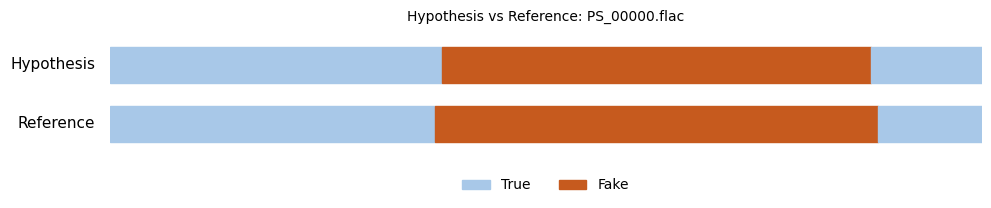

In [22]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

@torch.no_grad()
def plot_hypothesis_vs_reference(model, dataset, idx=0):
    feat, labels, mask, fname = dataset[idx]
    feat_b = feat.unsqueeze(0).to(DEVICE)
    mask_b = mask.unsqueeze(0).to(DEVICE)
    logits = model(feat_b, mask_b)
    hyp = logits.argmax(dim=-1).squeeze(0).cpu().numpy()
    ref = labels.numpy()
    n = int(mask.sum().item())
    hyp, ref = hyp[:n], ref[:n]

    fig, ax = plt.subplots(figsize=(10, 2.2))
    true_color, fake_color = "#a8c8e8", "#c65a1e"

    for row_y, seq, label in [(1, hyp, "Hypothesis"), (0, ref, "Reference")]:
        start = 0
        for i in range(1, n + 1):
            if i == n or seq[i] != seq[start]:
                color = fake_color if seq[start] == 1 else true_color
                ax.add_patch(plt.Rectangle((start, row_y - 0.3), i - start, 0.6, color=color))
                start = i
        ax.text(-2, row_y, label, ha="right", va="center", fontsize=11)

    ax.set_xlim(0, n)
    ax.set_ylim(-0.6, 1.6)
    ax.axis("off")
    ax.legend(handles=[mpatches.Patch(color=true_color, label="True"),
                        mpatches.Patch(color=fake_color, label="Fake")],
              loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=2, frameon=False)
    plt.title(f"Hypothesis vs Reference: {fname}", fontsize=10)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "hypothesis_vs_reference_example_mfcc.png"), dpi=150)
    plt.show()


plot_hypothesis_vs_reference(localization_model, loc_val_ds, idx=0)
